# TP 2 - Séance 1
## Filtrage fréquentiel 2D

Équipe #0
- Nom, Prénom (Matricule)
- Nom, Prénom (Matricule)

In [1]:
# Importe les modules qui seront utilisés dans le laboratoire.
from typing import Optional, Tuple
import numpy as np
from scipy.ndimage import convolve
from IPython.display import clear_output
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.pyplot import imread

%matplotlib inline
# Étend la taille des figures
plt.rcParams["figure.figsize"] = (18, 8)

<font color='green'>Conseil : </font>Nous vous conseillons d'utiliser la [plateforme](https://clementpla.github.io/ComputerVisionToolbox/home) de traitement d'image présentée par Clément Playout dans le cours, particulièrement le module sur la transformée de Fourier 2D. Vous pouvez vous-même créer des signaux sinusoïdaux (en cliquant sur le bouton Draw sin(x)), changer l'angle, et visualiser le résultat de la fft 2D. 

# Exercice I : FFT de signaux théoriques 2D

On étudie le signal: $S_1(x,y)=\cos(2\pi\,(x f_x + y f_y))$ paramétré par les fréquences $f_x$ et $f_y$.

On vous fournit les fonctions ```S1(fx,fy)``` qui calcule le signal avec un échantillonage $F_e=100 px/mm$, et ```plot_fft2(fft_signal)``` qui prend en paramètre une transformée de Fourier et affiche le spectre associé.

In [2]:
def plot_fft2(
    fft_signal: np.ndarray,
    Fe: Optional[float] = None,
    grid: bool = True,
    logscale: bool = False,
    ax: Optional[matplotlib.axes.Axes] = None,
) -> None:
    """Trace le spectre d'un signal à partir de sa transformée de Fourier.

    Args:
        fft_signal (np.ndarray): Transformée de Fourier du signal à afficher (array 2D complexe).
        Fe (float, optionnel): Fréquence d'échantillonage du signal. La valeur par défaut est None.
        grid (bool, optionnel): Si vrai, affiche une grille sur le spectre. La valeur par défaut est True.
        logscale (bool, optionnel): Si vrai, les intensités du spectre sont affichées en échelle logarithmique. La
            valeur par défaut est False
        ax : Si fourni, le spectre sera tracé dans ce subplot. La valeur par défaut est None.
    """
    # Si aucun système d'axes est fourni on en créé un.
    if ax is None:
        fig, ax = plt.subplots()

    # On calcule les bornes des abscisses et des ordonnées à partir de Fe.
    H, W = fft_signal.shape
    if Fe is not None:
        ymax = (H - (0 if H % 2 else 1)) / (2 * H) * Fe
        xmax = (W - (0 if W % 2 else 1)) / (2 * W) * Fe
        extent = (-Fe / 2, xmax, ymax, -Fe / 2)
    else:
        extent = (-W // 2, W // 2 + (W % 2), H // 2, -H // 2 - (H % 2))

    if grid:
        # Si grid est vrai, on affiche la grille
        ax.grid(color="#bbb", linestyle="dotted")
        unit = " (en $mm^{-1}$)" if Fe is not None else ""
        ax.set_xlabel("U" + unit)
        ax.set_ylabel("V" + unit)
    else:
        # Sinon on désactive les axes
        ax.axis("off")

    # On calcule le spectre (le module de la transformée de Fourier).
    fft_displayed = np.abs(fft_signal)

    if not logscale:
        # Si logscale est faux on affiche le spectre avec une colorbar
        graph = ax.imshow(fft_displayed, cmap="inferno", extent=extent)
        plt.colorbar(graph, ax=ax, fraction=0.0467, pad=0.02)
    else:
        # Sinon on nivelle les intensités trop élevées (0.1% des intensités les plus fortes)
        fft_displayed = np.clip(fft_displayed, 0, np.percentile(fft_displayed, 99.9))
        # et on affiche le spectre en intensités logarithmiques
        fft_displayed = np.log(1 + fft_displayed)
        graph = ax.imshow(fft_displayed, cmap="inferno", extent=extent, vmin=0)


def S1(fx: float, fy: float) -> np.ndarray:
    """Génère le signal S1 sur [-1, 1] x [-1, 1] avec une fréquence d'échantillonnage de 100 px/mm.

    Args:
        fx (float): Fréquence du signal en x.
        fy (float): Fréquence du signal en y.

    Returns:
        np.ndarray: Le signal S1.
    """
    y = np.arange(-1, 1, 1 / 100)
    x = np.arange(-1, 1, 1 / 100)
    # On définit une grille de coordonnées x et y.
    x, y = np.meshgrid(x, y)

    # On calcule le signal pour chaque point de cette grille, c'est-à-dire pour chaque pixel de l'image.
    return np.cos(2 * np.pi * (x * fx + y * fy))

1a.Implémentez la fonction `compute_fft2(signal)` qui prend en argument une image et calcule sa transformée de Fourier (normalisée et avec son origine centrée).  

1b.En prenant $f_x = 13 \text{ mm}^{-1}$ et $f_y=0$. Affichez le signal $S_1(x,y)$ et son spectre à l'aide de `plot_fft2()`. Vérifier la position des pics et leur amplitude (donnée par la colorbar). Les valeurs des positions et d'amplitude sont-elles celles attendues ?

_(Pour gagner du temps dans la suite de l'exercice, on conseille d'encapsuler le code d'affichage d'un signal et de son spectre dans une fonction.)_

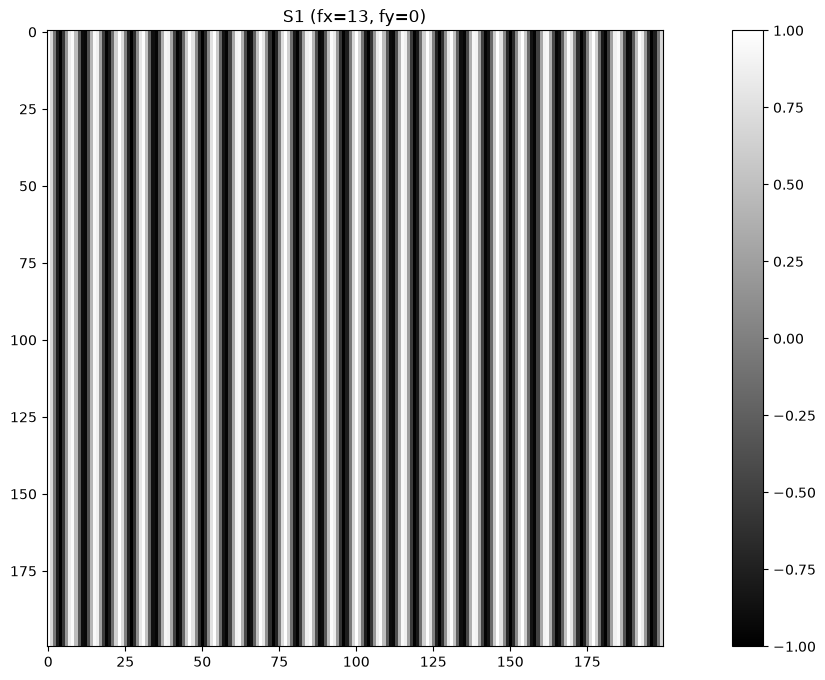

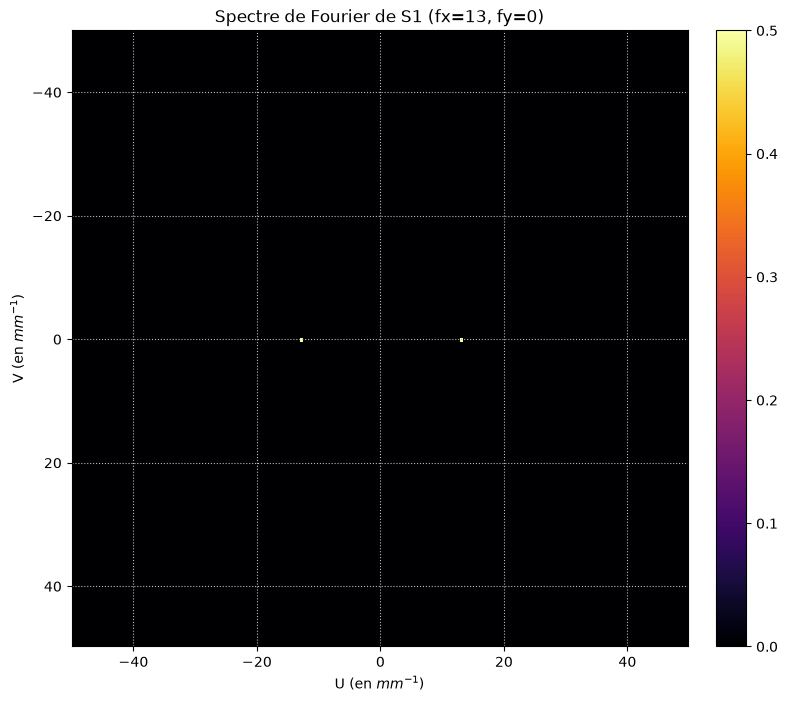

In [13]:
#1a
def compute_fft2(signal):
    F = np.fft.fft2(signal, norm="forward")
    F = np.fft.fftshift(F)
    return F
#1b
signal = S1(13, 0)

# Calculer sa transformée de Fourier
F = compute_fft2(signal)

def plot_signal_et_fft(signal, titre="Signal"):
    # Afficher le signal
    plt.figure()
    plt.imshow(signal, cmap="gray")
    plt.title(titre)
    plt.colorbar()

    # Afficher le spectre
    F = compute_fft2(signal)
    plot_fft2(F, Fe=100)
    plt.title("Spectre de Fourier de " + titre)

    plt.show()


plot_signal_et_fft(signal, "S1 (fx=13, fy=0)")

**2a.** Affichez $S_1$ et son spectre pour $f_x=0$, $f_y=13 \text{ px}^{-1}$ puis pour $f_x=5 \text{ px}^{-1}$, $f_y=12 \text{ px}^{-1}$.   

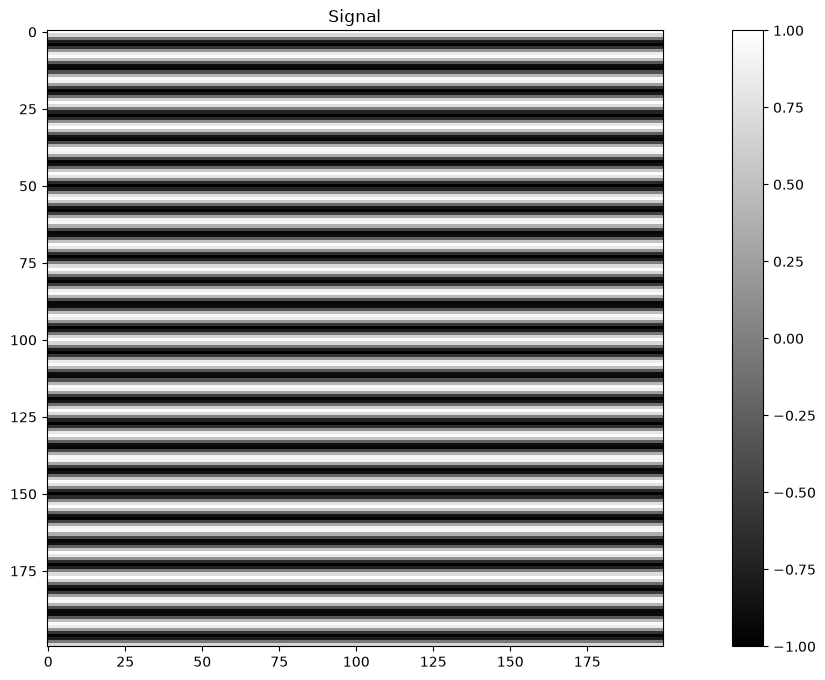

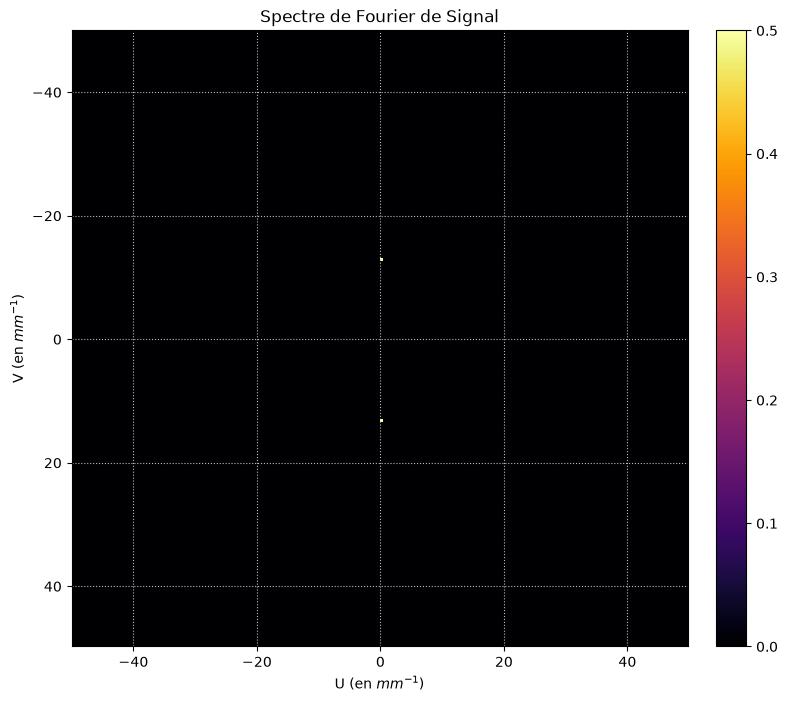

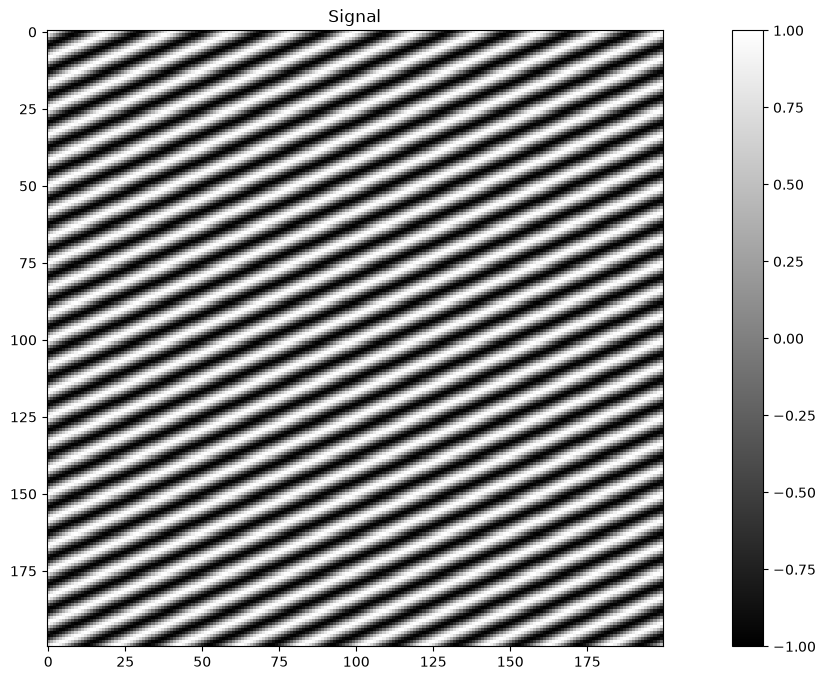

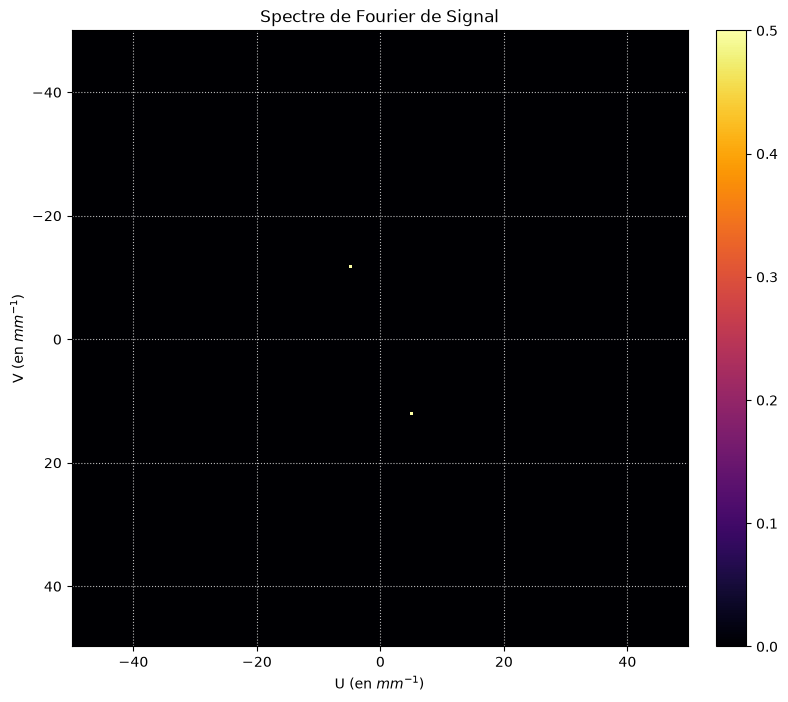

In [14]:
# Premier cas : fx = 0, fy = 13
signal1 = S1(0, 13)
plot_signal_et_fft(signal1)

# Deuxième cas : fx = 5, fy = 12
signal2 = S1(5, 12)
plot_signal_et_fft(signal2)

**2b.** Quel est l'effet d'une rotation de l'image sur son spectre?

In [ ]:
# Une rotation de l'image entraîne une rotation correspondante de son spectre de Fourier. Les pics changent d'orientation, mais conservent leur distance au centre et leur amplitude.

La prochaine question étudie le signal: $S_2(x,y) = cos(2\pi f r)$ où $r=\sqrt{x^2+y^2}$.

**3a.** En vous inspirant de l'implémentation de ```S1(fx,fy)```, définissez ```S2(f)``` (pour mieux comprendre voir la doc de [np.meshgrid](https://numpy.org/doc/stable/reference/generated/numpy.meshgrid.html)).  
Affichez le signal et son spectre pour $f=20$ et pour $f=40$.   

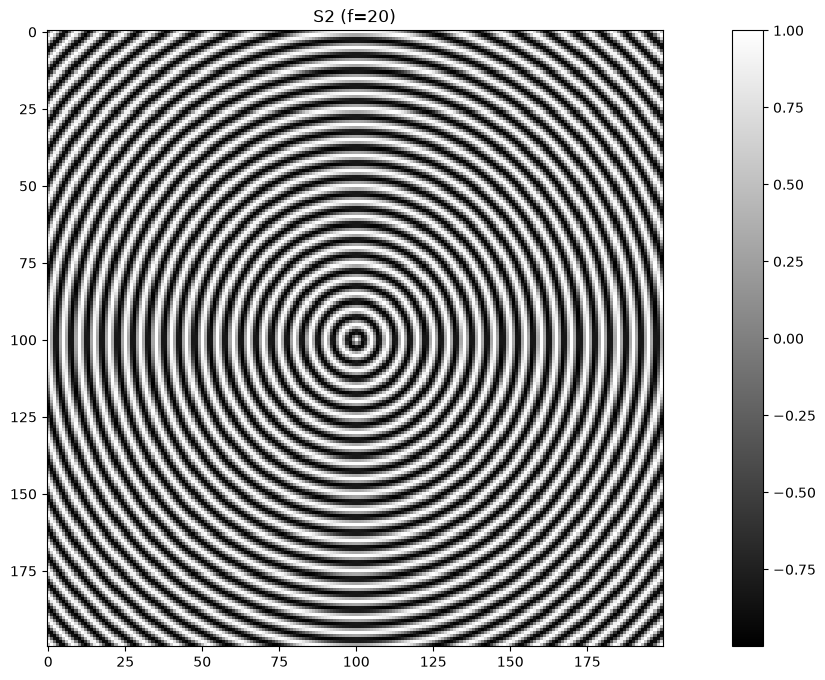

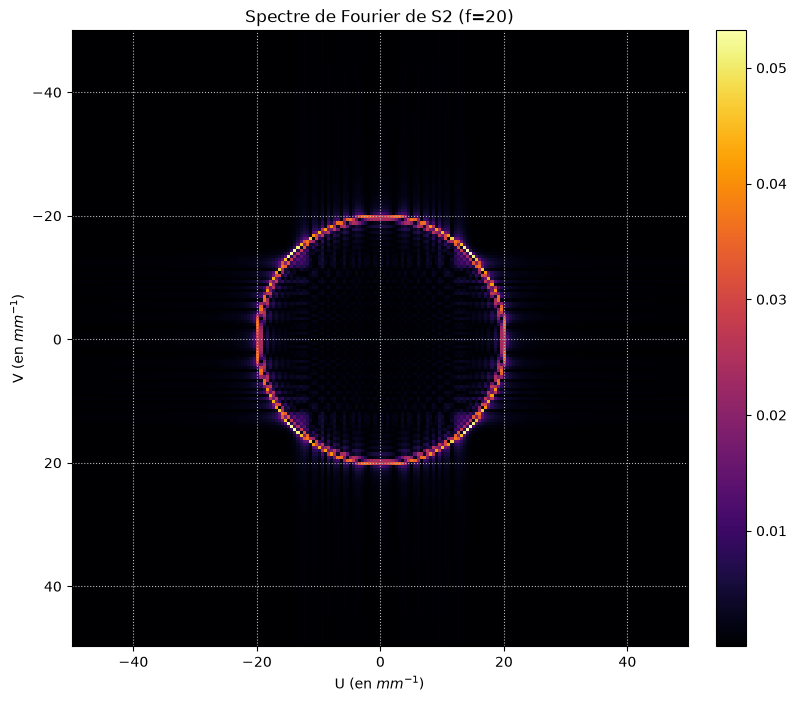

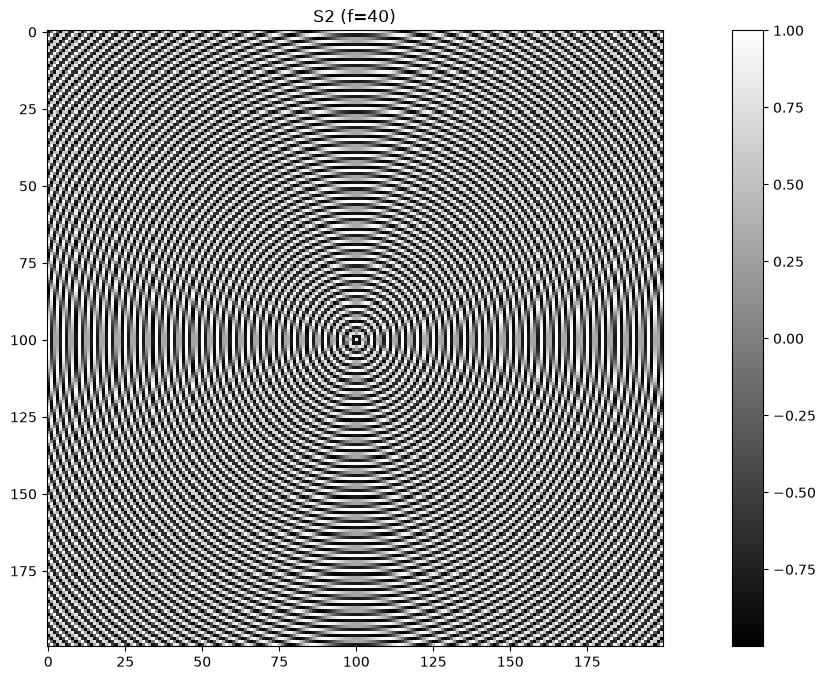

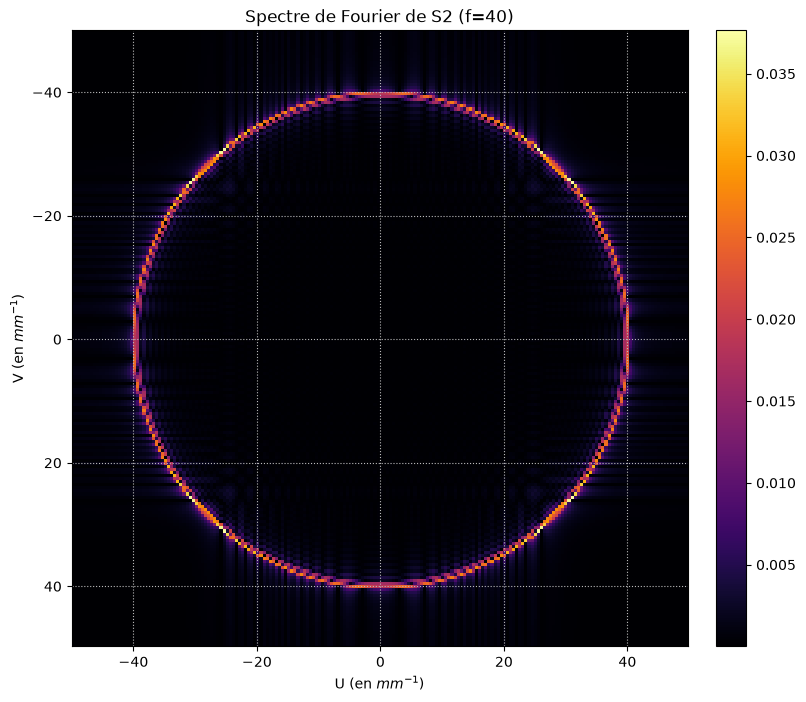

In [17]:
def S2(f):
    x = np.arange(-1, 1, 1 / 100)
    y = np.arange(-1, 1, 1 / 100)

    x, y = np.meshgrid(x, y)

    r = np.sqrt(x**2 + y**2)

    return np.cos(2 * np.pi * f * r)
# Cas 1 : f = 20
plot_signal_et_fft(S2(20),"S2 (f=20)")

# Cas 2 : f = 40
plot_signal_et_fft(S2(40),"S2 (f=40)")



**3b.** Quel est l'effet d'un rétrécissement de l'image sur son spectre? 

In [ ]:
# Un rétrécissement de l'image entraîne un élargissement de son spectre de Fourier. En effet, lorsque les motifs de l'image deviennent plus serrés, leurs fréquences spatiales augmentent et les composantes du spectre s'éloignent du centre.

**3c.** Affichez le signal et le spectre pour $f=120$. Expliquez l'allure du spectre et les aberrations visibles sur le signal.

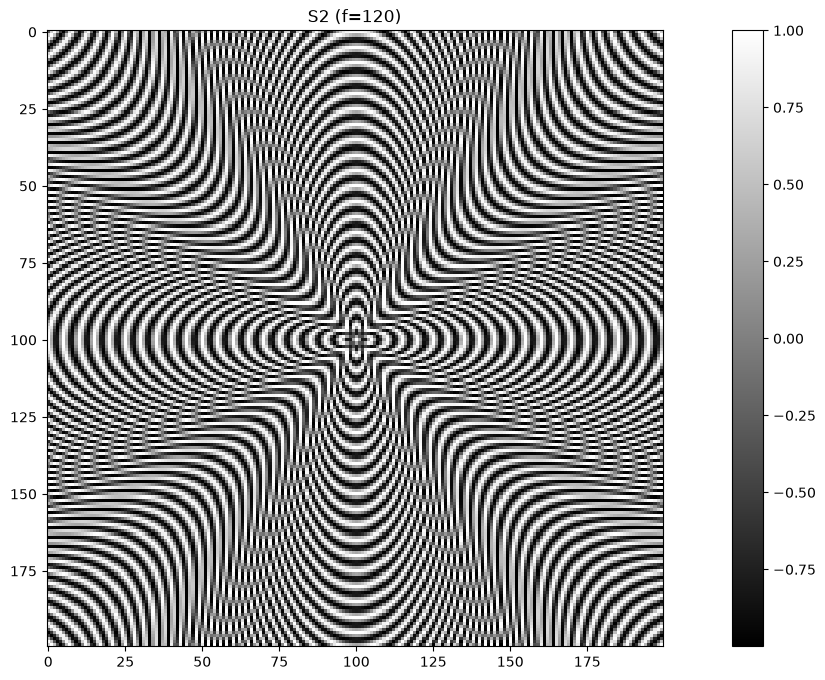

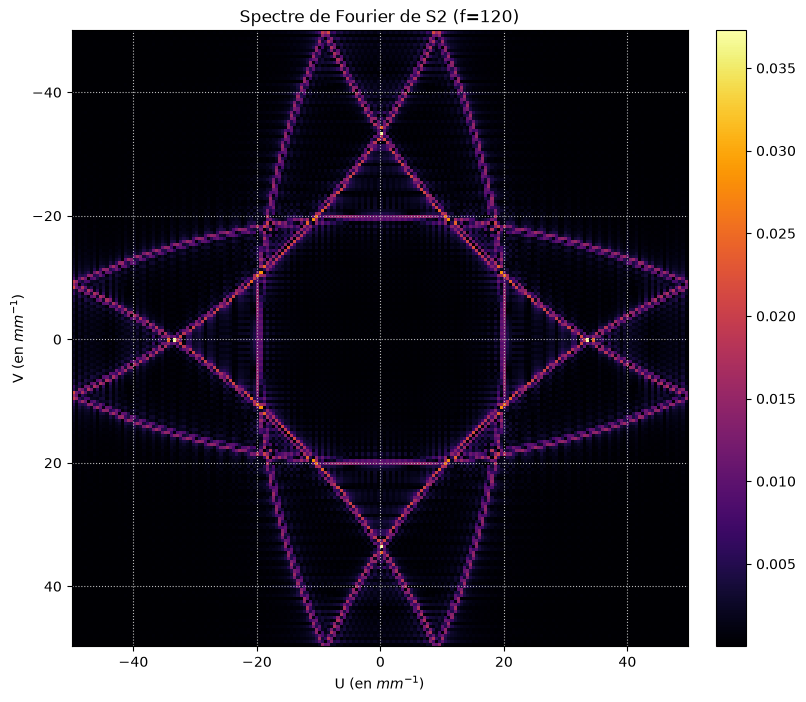

In [18]:
signal = S2(120)
plot_signal_et_fft(signal, "S2 (f=120)")
# La fréquence du signal dépasse la fréquence de Nyquist, qui est de 50 mm⁻¹ (Fe / 2 = 100 / 2).Il se produit donc un repliement spectral (aliasing) : les hautes fréquences se replient dans la zone fréquentielle observable, ce qui déforme le spectre.
# Sur l'image, ce phénomène provoque l'apparition de motifs parasites et la déformation des cercles concentriques, car le signal est insuffisamment échantillonné.

____

# Exercice II : Filtrage spectral

Cet exercice étudie une image angiographique du réseau coronaire: c'est-à-dire une radiographie des artères qui alimentent le coeur dans lesquelles est injecté un agent de contraste.

Tout d'abord, on souhaite définir une fonction de création de gaussienne.    
On rappelle la formule de la gaussienne en 2D d'écart-type $\sigma$ et de centre $(x_0, y_0)$: $G(x,y) = \exp\left(\dfrac{-r^2}{2 \sigma^2}\right)$ avec $r=\sqrt{(x-x_0)^2+(y-y_0)^2}$.

**1a.** Implémentez la fonction `gaussian(std, size, x0=0, y0=0)` qui renvoie une matrice de taille `size` contenant les valeurs d'une gaussienne d'écart-type `std` et centrée sur (`x0`, `y0`) avec le point central comme origine: (0,0).

**1b.** Calculez une gaussienne centrée, d'écart-type 7 dans une matrice 300x300. Affichez son image et son spectre.

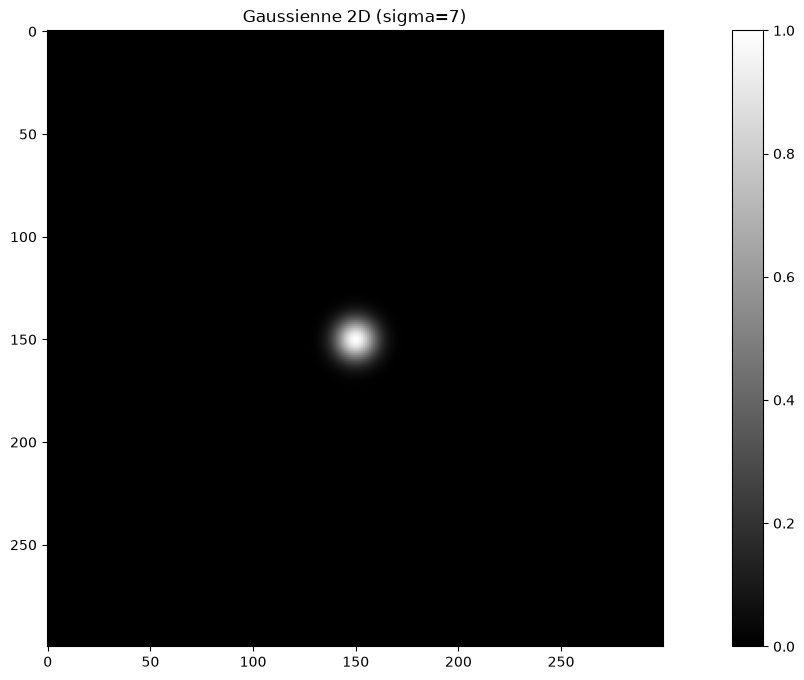

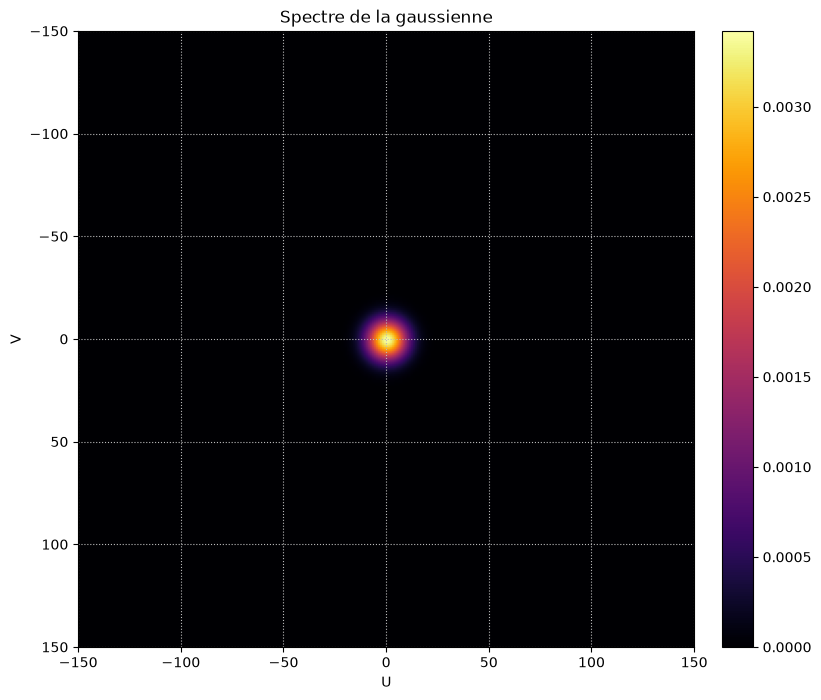

In [19]:
def gaussian(std: float, size: int, x0: float = 0, y0: float = 0) -> np.ndarray:
    # Créer les coordonnées centrées en (0,0)
    x = np.arange(size) - size // 2
    y = np.arange(size) - size // 2

    # Créer la grille 2D
    x, y = np.meshgrid(x, y)

    # Calculer le carré de la distance au centre
    r2 = (x - x0)**2 + (y - y0)**2

    # Calculer la gaussienne
    G = np.exp(-r2 / (2 * std**2))

    return G
# Créer la gaussienne
G = gaussian(7, 300)

# Afficher la gaussienne
plt.figure()
plt.imshow(G, cmap="gray")
plt.title("Gaussienne 2D (sigma=7)")
plt.colorbar()

# Calculer et afficher son spectre
F = compute_fft2(G)
plot_fft2(F)
plt.title("Spectre de la gaussienne")

plt.show()

**2.** Chargez l'image `angiographie_bruit.png`. Affichez l'image et son spectre.   
Identifiez sur le spectre les raies qui sont responsables des rayures diagonales sur l'angiographie (donnez les coordonnées des points concernés). 

_Pour améliorer la lisibilité du spectre, activez l'option `logscale=True`. Cette option sera laissée active dans les prochaines questions pour l'affichage de tous les spectres issus de l'image._

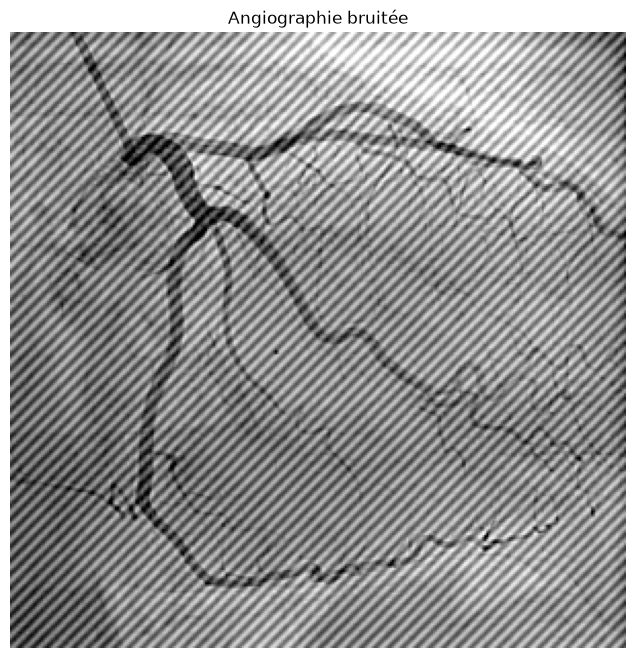

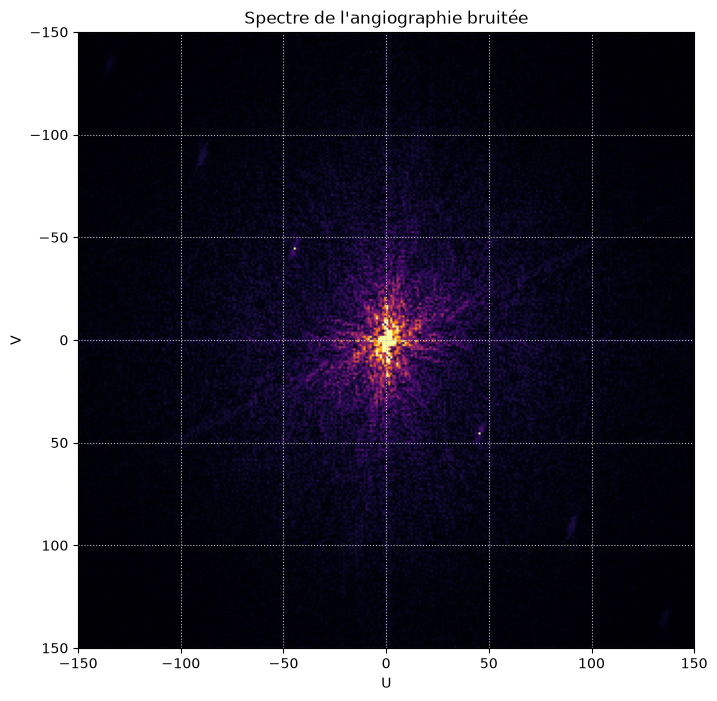

In [20]:
# Charger l'image
img = plt.imread("angiographie_bruit.png")

# Afficher l'image
plt.figure()
plt.imshow(img, cmap="gray")
plt.title("Angiographie bruitée")
plt.axis("off")

# Calculer le spectre
F = compute_fft2(img)

# Afficher le spectre en échelle logarithmique
plot_fft2(F, logscale=True)
plt.title("Spectre de l'angiographie bruitée")

plt.show()

**3.** À l'aide de la fonction ``gaussian(std, size, x0=0, y0=0)``, concevez un masque pour filtrer ces raies directement dans le domaine de Fourier (on pourra prendre un écart type de 3 pixels.) Appliquez le masque à la transformée de Fourier de l'image.   
Affichez le masque et le spectre filtré.

**4.** Implémentez la fonction `compute_ifft2(fft_signal)` qui prend en argument la transformée de Fourier d'une image et renvoie l'image reconstituée par transformée de Fourier inverse. Reconstituez et affichez l'angiographie nettoyée de ses rayures diagonales.

Pour la suite de l'exercice on travaillera sur l'angiographie nettoyée ou sur son spectre. Sa transformée de Fourier sera notée $T_0$.

In [ ]:
def compute_ifft2(fft_signal: np.ndarray) -> np.ndarray:
    # Avant d'être basculée dans le domaine spatial, les fréquences de la transformée de Fourier du signal 
    # doivent être permutées avec np.fft.ifftshift pour être à nouveau comprises entre 0 <= f < Fe.
    # La transformée de Fourier inverse d'une image est calculée par np.fft.ifft2(img). 
    # return ...

On souhaite appliquer un filtre passe-bas dont la réponse fréquentielle est une gaussienne centrée sur l'origine d'écart-type 25.

**5.** Créez le masque gaussien correspondant, appliquez le à la transformée de Fourier de l'image et reconstituez la. Affichez l'image reconstituée et son spectre. 

On notera $T_{\text{LF}}$ la transformée de Fourier après ce filtrage.

**6a.** Calculez l'intensité des fréquences qui ont été retirées du spectre à la question précédente, c'est-à-dire la transformée de Fourier $T_{\text{HF}}$ telle que $T_0 = T_{\text{LF}} + T_{\text{HF}}$.   
Affichez l'image reconstituée et son spectre. 

**6b.** Quel est le type de ce filtrage?

**7.** Créez un masque gaussien centré d'écart-type 1.91 pixels, de taille 11x11 et normalisé pour que sa somme soit 1. Convoluez ce masque avec l'image nettoyée à la question 4.   
Affichez l'image filtrée et son spectre.

On rappelle que la transformée de Fourier d'une gaussienne d'écart-type $\sigma_0$ est un gaussienne d'écart-type $\frac{1}{2 \pi \sigma_0}$. Notons aussi que l'écart-type du masque de la question 5 en $\text{px}^{-1}$ est de $\frac{25}{300}$, c'est-à-dire l'écart-type de la gaussienne divisé par le nombre de pixel de la largeur (ou de la hauteur) du spectre.


**8a.** Démontrez mathématiquement l'équivalence entre les filtrages réalisés aux question 5 et 7.



**8b.** Avec quel masque faut-il convoluer l'image nettoyée pour réaliser un filtrage passe-haut équivalent à celui de la question 6 mais dans le domaine spatial?

**Bonus**

Calculez et affichez la transformée de Fourier de l'image `cellules.png`. Cette image représente une certaine lignée cellulaire imagée au microscope. Est-ce que la méthode implémentée dans l'exercice II permettrait d'éliminer les lignes qui perturbent l'image ? En quoi le spectre de la FFT est-il différent de l'image angiographique de l'exercice II ?
